<a href="https://colab.research.google.com/github/mmm10138/Machine-Learning/blob/main/HW_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In this homework we solve optimal control (OC) and stochastic optimal control (SOC) problems using a direct optimization method.

# Preliminaries

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import random

def set_seed(seed_value):
    # Python random
    random.seed(seed_value)

    # NumPy random
    np.random.seed(seed_value)

    # PyTorch random
    torch.manual_seed(seed_value)

    # For GPU (if using CUDA)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed_value)
        torch.cuda.manual_seed_all(seed_value)

    # Ensure deterministic behavior
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Part 1: Deterministic OC

Consider the following (deterministic) OC problem:
$$
  J(a) = \int_0^T \frac{1}{2}\left((x(t) - 3)^2 + a(t)^2\right) \, dt + \frac{1}{2}(x(T) - 1)^2,
$$
with control $t \mapsto a(t)$ and state $t \mapsto x(t)$ satisfying the dynamics:
$$
    \dot{x}(t) = a(t), \quad x(0) = 0.
$$
Because there is no noise, we focus on controls that are functions of $t$ only.

In [3]:
# Neural network for control alpha(t, x)
class ControlNetworkTime(nn.Module):
    def __init__(self):
        super(ControlNetworkTime, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64),  # Input: (t, x)
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1)  # Output: alpha(t, x)
        )

    def forward(self, t):
        return self.net(t)

TODO: Remark: The cost should be computed **before** updating the state.

In [4]:
# Training the control network
def train_control_network(control_net, T, dt, num_iterations=5000, lr=0.001, x0=0.0):
    optimizer = optim.Adam(control_net.parameters(), lr=lr)
    loss_history = []
    time_points = int(T / dt)

    for iteration in range(num_iterations):
        # Reset trajectory and cost
        x = torch.tensor([[x0]], dtype=torch.float32, requires_grad=True)  # Initial condition
        total_cost = 0.0

        # Generate trajectory
        for n in range(time_points):
            t = torch.tensor([[n * dt]], dtype=torch.float32)
            alpha = control_net(t) #Use neural network
            cost = 0.5*((x-3.0)**2+alpha**2) #Running cost
            total_cost += cost * dt

            # Update state
            dx = alpha*dt
            x = x + dx

        # Add terminal cost
        terminal_cost = 0.5*(x-1.0)**2 #Terminal cost
        total_cost += terminal_cost

        # Backpropagation
        optimizer.zero_grad()
        total_cost.backward()
        optimizer.step()

        # Store loss
        loss_history.append(total_cost.item())

        # Print progress
        if iteration % 100 == 0 or iteration == num_iterations - 1:
            print(f"Iteration {iteration}/{num_iterations}, Loss: {total_cost.item():.4e}")

    # Plot losses
    plt.figure(figsize=(10, 6))
    plt.plot(loss_history)
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.title("Loss During Training")
    plt.show()

    return control_net, loss_history

In [5]:
# Plotting functions
def plot_trajectory_and_control(control_net, T, dt, x0=0.0):
    x = torch.tensor([[x0]], dtype=torch.float32)
    trajectory = [x.item()]
    control_values = []
    time_values = np.arange(0, T, dt)

    # Generate trajectory
    for t in time_values:
        t_tensor = torch.tensor([[t]], dtype=torch.float32)
        alpha = control_net(t_tensor)
        control_values.append(alpha.item())
        x = x + alpha * dt
        trajectory.append(x.item())

    # Plot trajectory and control
    plt.figure(figsize=(10, 6))
    plt.plot(time_values, trajectory[:-1], label="Optimal Trajectory $x^*(t)$", c="blue")
    plt.plot(time_values, control_values, label="Optimal Control $\\alpha^*(t, x^*)$", ls=":", c="red")
    plt.xlabel("Time $t$")
    plt.ylabel("$x(t)$ / $\\alpha(t, x)$")
    plt.title("Optimal Trajectory and Control")
    plt.legend()
    plt.show()

Iteration 0/500, Loss: 1.2451e+02
Iteration 100/500, Loss: 6.4339e+00
Iteration 200/500, Loss: 5.9720e+00
Iteration 300/500, Loss: 5.8527e+00
Iteration 400/500, Loss: 5.8227e+00
Iteration 499/500, Loss: 5.8120e+00


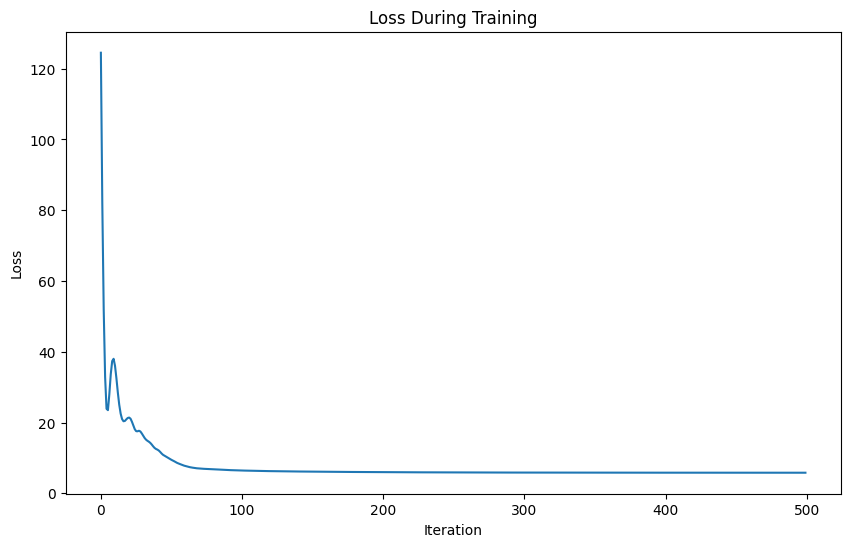

In [6]:
# Training
T = 10.0
dt = 0.1
n_iter = 500
set_seed(42)
control_net = ControlNetworkTime()
trained_control_net, loss_history = train_control_network(control_net, num_iterations=n_iter, T=T, dt=dt)

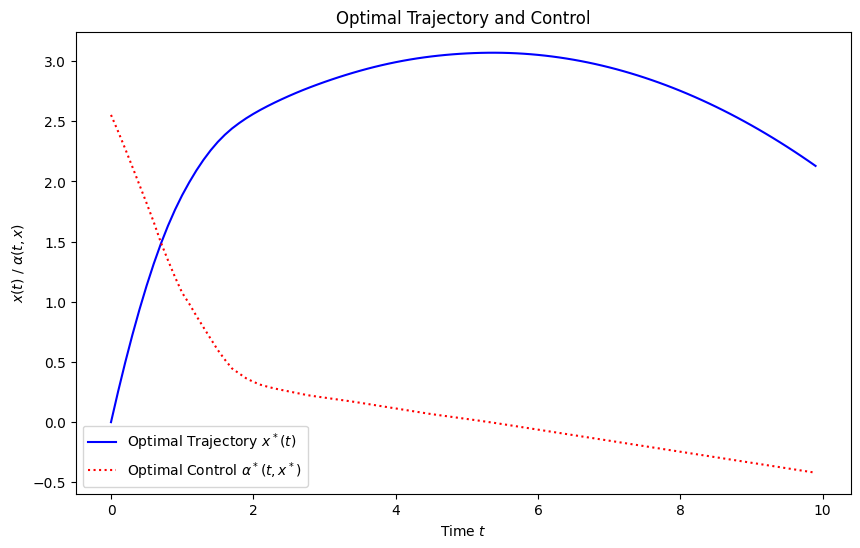

In [7]:
# Plotting
plot_trajectory_and_control(trained_control_net, T=T, dt=dt)

# Part 2: Stochastic OC

Now we consider a stochastic version of the previous OC problem.

Consider the following SOC problem:
$$
  J(\alpha) = \mathbb{E} \left[ \int_0^T \frac{1}{2}\left((X_t - 3)^2 + \alpha(t,X_t)^2\right) \, dt + \frac{1}{2}(X_T - 1)^2 \right],
$$
with control $(t,x) \mapsto \alpha(t,x)$ and state $t \mapsto X_t$ satisfying the dynamics:
$$
    dX_t = \alpha(t,X_t)dt + \sigma dW_t, \quad X_0 \sim \mu_0 = \mathcal{N}(0,\sigma_0).
$$
Now there is noise in the dynamics so we consider controls that are functions of $t$ and $x$, so that we know which action to take in any possible state.

## Training method

In [8]:
# Define Neural Network for the Control
class ControlNetworkTimeSpace(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(ControlNetworkTimeSpace, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, t, x):
        tx = torch.cat([t, x], dim=-1)  # Concatenate time and state
        return self.net(tx)

In [9]:
def simulate_trajectory(control_nn, x0, dW, dt, T, sigma):
    """
    Simulates a batch of trajectories using the given control neural network.

    Parameters:
        control_nn (nn.Module): The neural network representing the control.
        x0 (torch.Tensor): Initial states, shape (batch_size, 1).
        dW (torch.Tensor): Increments of the Brownian motion, shape (batch_size, timesteps, 1).
        dt (float): Time step.
        T (float): Final time.
        sigma (float): Diffusion coefficient.

    Returns:
        trajectories (torch.Tensor): State trajectories, shape (batch_size, timesteps + 1, 1).
        controls (torch.Tensor): Control actions, shape (batch_size, timesteps, 1).
        total_cost (torch.Tensor): Total cost for each trajectory, shape (batch_size,).
    """
    timesteps = dW.shape[1]
    batch_size = x0.shape[0]
    x = x0.clone()
    trajectories = [x]
    controls = []
    costs = []

    for t_idx in range(timesteps):
        t = torch.ones(batch_size, 1) * (t_idx * dt)
        a = control_nn(t,x) #Use neural network
        x = x + a * dt + sigma * dW[:, t_idx, :]
        trajectories.append(x)
        controls.append(a)
        cost = 0.5*((x-3.0)**2+a**2) #Running cost
        costs.append(cost)

    terminal_cost = 0.5*(x-1.0)**2 #Terminal cost
    total_cost = torch.sum(torch.cat(costs, dim=1), dim=1) + terminal_cost.squeeze()
    return torch.stack(trajectories, dim=1), torch.stack(controls, dim=1), total_cost

In [10]:
def train_stochastic_control(control_nn, num_epochs, batch_size, learning_rate, dt, T, sigma, sigma0, test_x0, test_dW):
    """
    Trains the control neural network using stochastic trajectories.

    Parameters:
        control_nn (nn.Module): Neural network representing the control.
        num_epochs (int): Number of training epochs.
        batch_size (int): Size of the minibatch for training.
        learning_rate (float): Learning rate for the optimizer.
        dt (float): Time step.
        T (float): Final time.
        sigma (float): Diffusion coefficient.
        sigma0 (float): Standard deviation for initial distribution.
        test_x0 (torch.Tensor): Fixed initial states for testing.
        test_dW (torch.Tensor): Fixed Brownian increments for testing.

    Returns:
        train_losses (list): Training losses over epochs.
        test_losses (list): Testing losses over epochs.
        control_nn (nn.Module): Trained control neural network.
    """
    optimizer = optim.Adam(control_nn.parameters(), lr=learning_rate)
    train_losses = []
    test_losses = []

    timesteps = int(T / dt)

    for epoch in range(num_epochs):
        # Generate random x0 and dW for training
        x0 = torch.randn(batch_size, 1) * sigma0  # Random initial states (Gaussian)
        dW = torch.randn(batch_size, timesteps, 1) * np.sqrt(dt)  # Brownian increments

        # Simulate training trajectories
        _, _, train_loss = simulate_trajectory(control_nn,x0,dW,dt,T,sigma) #Call simulate_trajectory
        loss = torch.mean(train_loss)

        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

        # Compute test loss every 100 epochs
        if epoch % 100 == 0 or epoch == num_epochs - 1:
            with torch.no_grad():
                _, _, test_loss = simulate_trajectory(control_nn, test_x0, test_dW, dt, T, sigma)
                test_losses.append(torch.mean(test_loss).item())
                print(f"Epoch {epoch}/{num_epochs}, Train Loss: {loss.item():.3e}, Test Loss: {test_losses[-1]:.3e}")

    return train_losses, test_losses, control_nn

In [11]:
# Plotting functions
def plot_trajectory_and_control_tx(control_net, T, dt, x0=0.0):
    x = torch.tensor([[x0]], dtype=torch.float32)
    trajectory = [x.item()]
    control_values = []
    time_values = np.arange(0, T, dt)

    # Generate trajectory
    for t in time_values:
        t_tensor = torch.tensor([[t]], dtype=torch.float32)
        alpha = control_net(t_tensor, x)
        control_values.append(alpha.item())
        x = x + alpha * dt
        trajectory.append(x.item())

    # Plot trajectory and control
    plt.figure(figsize=(10, 6))
    plt.plot(time_values, trajectory[:-1], label="Optimal Trajectory $x^*(t)$", c="blue")
    plt.plot(time_values, control_values, label="Optimal Control $\\alpha^*(t, x^*)$", ls=":", c="red")
    plt.xlabel("Time $t$")
    plt.ylabel("$x(t)$ / $\\alpha(t, x)$")
    plt.title("Optimal Trajectory and Control")
    plt.legend()
    plt.show()

def plot_stochastic_results(control_nn, train_losses, test_losses, T, dt, sigma, test_every=100):
    # Plot the losses
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.semilogy(train_losses, label="Train Loss", color="blue", linestyle="-")
    plt.semilogy(np.arange(0, len(test_losses)) * test_every, test_losses, label="Test Loss", color="orange", linestyle="--")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.yscale("log")
    plt.legend()

    # Plot the control as a function of time and state
    test_t = torch.linspace(0, T, int(T / dt)).unsqueeze(1)
    test_x = torch.linspace(-2, 5, 100).unsqueeze(1)
    test_t_grid, test_x_grid = torch.meshgrid(test_t.squeeze(), test_x.squeeze())
    test_t_flat = test_t_grid.flatten().unsqueeze(1)
    test_x_flat = test_x_grid.flatten().unsqueeze(1)
    with torch.no_grad():
        test_a_flat = control_nn(test_t_flat, test_x_flat)

    plt.subplot(1, 2, 2, projection='3d')
    ax = plt.gca()
    ax.plot_surface(test_t_grid.numpy(), test_x_grid.numpy(), test_a_flat.view_as(test_t_grid).numpy(), cmap="viridis")
    ax.set_xlabel("Time")
    ax.set_ylabel("State")
    ax.set_zlabel("Control")
    plt.tight_layout()
    plt.show()

In [12]:
# Hyperparameters
dt = 0.1
T = 10.0
sigma0 = 1.0 # standard deviation of initial distribution
sigma = 0.1  # volatility coefficient
num_epochs = 1000
batch_size = 64
learning_rate = 0.001
hidden_dim = 64
test_size = 1000

# Setting seed
set_seed(42)

# Create fixed test data
test_x0 = torch.randn(test_size, 1) * sigma0  # Random initial states for testing
test_dW = torch.randn(test_size, int(T / dt), 1) * np.sqrt(dt)  # Fixed Brownian increments for testing

# Initialize Control Neural Network
control_nn = ControlNetworkTimeSpace(input_dim=2, hidden_dim=hidden_dim, output_dim=1)

# Train the model
train_losses, test_losses, control_nn = train_stochastic_control(control_nn, num_epochs, batch_size, learning_rate, dt, T, sigma, sigma0, test_x0, test_dW)

Epoch 0/1000, Train Loss: 3.112e+02, Test Loss: 2.854e+02
Epoch 100/1000, Train Loss: 5.794e+01, Test Loss: 5.314e+01
Epoch 200/1000, Train Loss: 5.315e+01, Test Loss: 5.008e+01
Epoch 300/1000, Train Loss: 4.595e+01, Test Loss: 4.990e+01
Epoch 400/1000, Train Loss: 4.630e+01, Test Loss: 4.984e+01
Epoch 500/1000, Train Loss: 4.918e+01, Test Loss: 4.983e+01
Epoch 600/1000, Train Loss: 4.878e+01, Test Loss: 4.982e+01
Epoch 700/1000, Train Loss: 5.078e+01, Test Loss: 4.982e+01
Epoch 800/1000, Train Loss: 4.946e+01, Test Loss: 4.981e+01
Epoch 900/1000, Train Loss: 5.469e+01, Test Loss: 4.981e+01
Epoch 999/1000, Train Loss: 4.438e+01, Test Loss: 4.981e+01


/usr/local/lib/python3.13/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4221.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


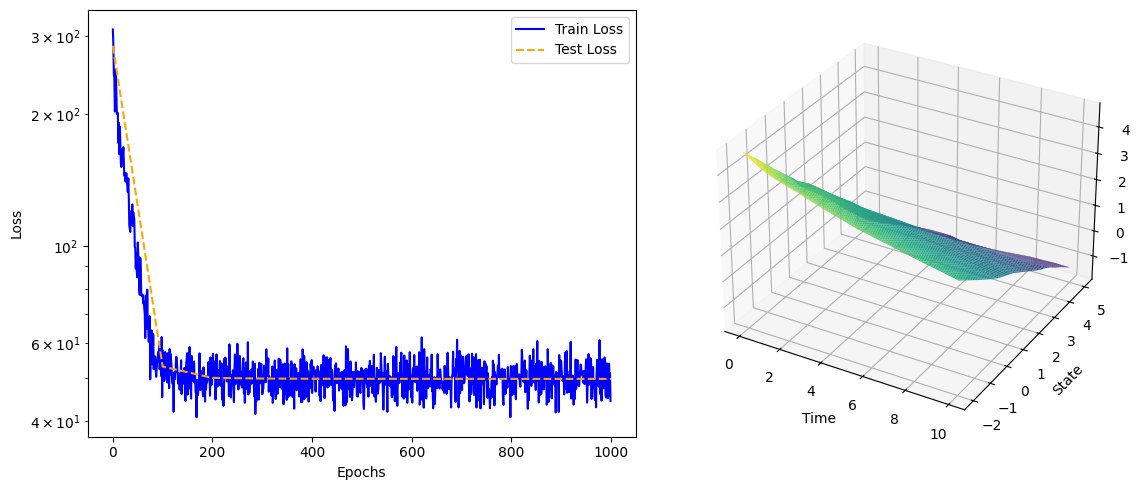

In [13]:
# Plot Results
plot_stochastic_results(control_nn, train_losses, test_losses, T, dt, sigma)

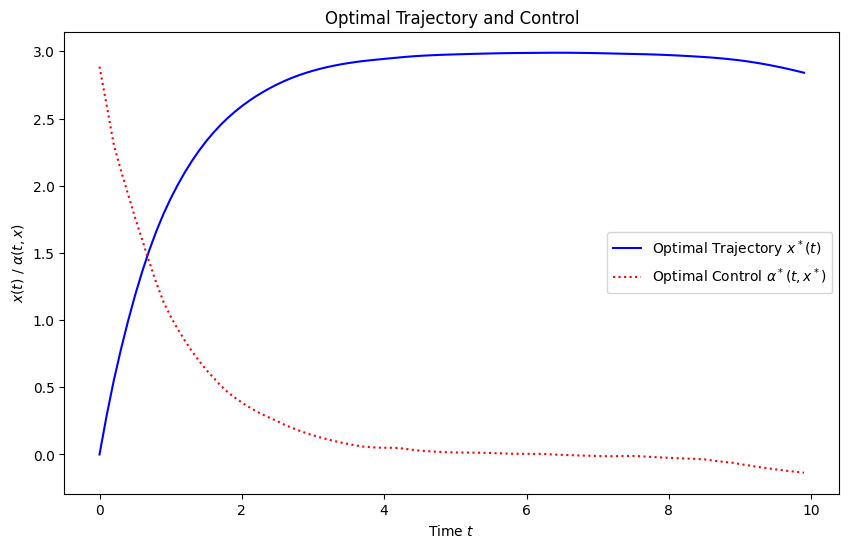

In [14]:
plot_trajectory_and_control_tx(control_nn, T=T, dt=dt, x0=0.0)

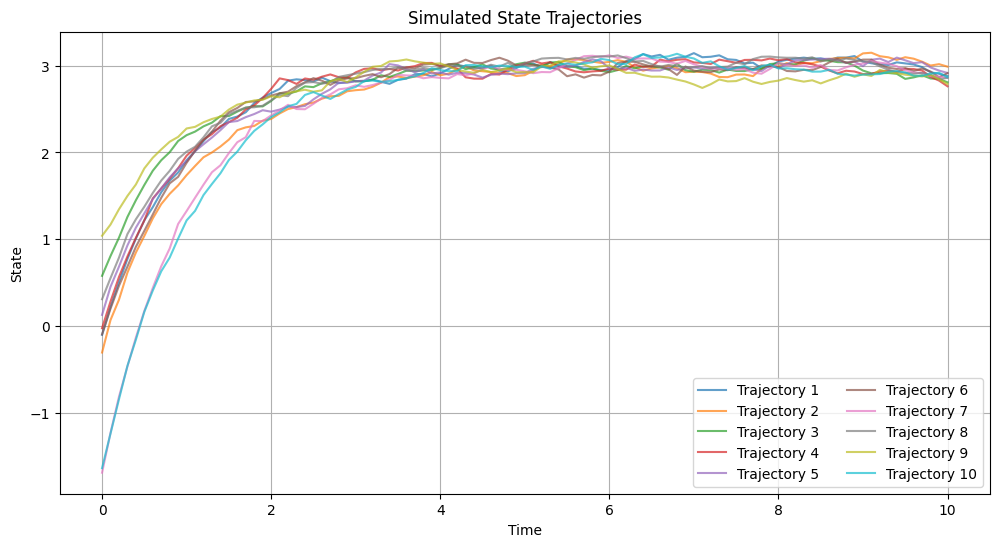

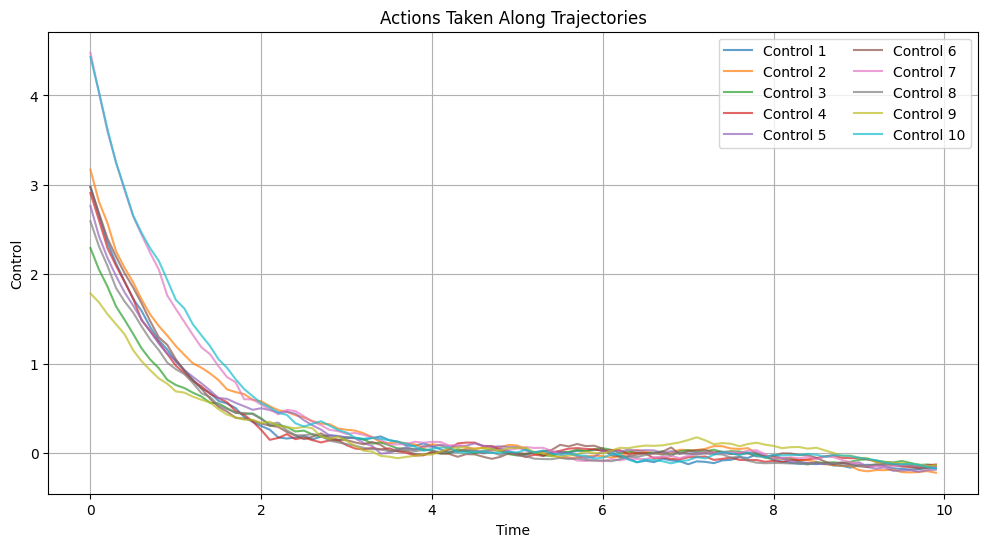

In [15]:
# Plot several (noisy) trajectories of optimal state and control
def plot_trajectory_and_control_stochastic(control_nn, num_trajectories, dt, T, sigma, sigma0):
    """
    Plots multiple stochastic trajectories and the corresponding controls using the learned control neural network.

    Parameters:
        control_nn (nn.Module): Trained control neural network.
        num_trajectories (int): Number of trajectories to simulate.
        dt (float): Time step.
        T (float): Final time.
        sigma (float): Diffusion coefficient.
        sigma0 (float): Standard deviation for initial distribution.
    """
    timesteps = int(T / dt)

    # Generate random initial states and Brownian motion increments
    x0 = torch.randn(num_trajectories, 1) * sigma0  # Random initial states (Gaussian)
    dW = torch.randn(num_trajectories, timesteps, 1) * np.sqrt(dt)  # Brownian increments

    # Simulate trajectories
    trajectories, controls, _ = simulate_trajectory(control_nn, x0, dW, dt, T, sigma)

    # Time points for plotting
    time_points = torch.arange(0, T + dt, dt)

    # Plot trajectories
    plt.figure(figsize=(12, 6))
    for i in range(num_trajectories):
        plt.plot(time_points, trajectories[i, :, 0].detach().numpy(), alpha=0.7, label=f"Trajectory {i+1}") # if i < 5 else "")
    plt.xlabel("Time")
    plt.ylabel("State")
    plt.title("Simulated State Trajectories")
    plt.legend(loc="best", ncol=2)
    plt.grid()
    plt.show()

    # Plot controls
    plt.figure(figsize=(12, 6))
    for i in range(num_trajectories):
        plt.plot(time_points[:-1], controls[i, :, 0].detach().numpy(), alpha=0.7, label=f"Control {i+1}") # if i < 5 else "")
    plt.xlabel("Time")
    plt.ylabel("Control")
    plt.title("Actions Taken Along Trajectories")
    plt.legend(loc="best", ncol=2)
    plt.grid()
    plt.show()

# Parameters for plotting
num_trajectories = 10

# Plot trajectories and controls
plot_trajectory_and_control_stochastic(control_nn, num_trajectories, dt, T, sigma, sigma0)

## Several runs (mean/stddev)

In [23]:
def run_multiple_experiments(N, ControlNetworkTimeSpace, train_stochastic_control, num_epochs, batch_size, learning_rate, dt, T, sigma, sigma0, test_size, hidden_dim, test_every=100):
    """
    Runs the stochastic control training algorithm N times, collects losses, and plots results.

    Parameters:
        N (int): Number of runs with different seeds.
        ControlNetworkTimeSpace (class): Neural network class for the control.
        train_stochastic_control (function): Training function for the stochastic control.
        num_epochs (int): Number of epochs for each training run.
        batch_size (int): Batch size for training.
        learning_rate (float): Learning rate for the optimizer.
        dt (float): Time step size.
        T (float): Total time duration.
        sigma (float): Diffusion coefficient.
        sigma0 (float): Standard deviation for the initial condition \( x_0 \).
        test_size (int): Number of trajectories in the testing set.
        hidden_dim (int): Number of hidden units in the control network.
        test_every (int): Number of epochs between two evaluations (testing).
    """
    all_train_losses = []
    all_test_losses = []

    for i in range(N):
        print("Run number ", i+1)

        # Set unique seed for each run
        set_seed(42 + i)

        # Create new fixed test data for each run
        test_x0 = torch.randn(test_size, 1) * sigma0  # Random initial states for testing
        test_dW = torch.randn(test_size, int(T / dt), 1) * np.sqrt(dt)  # Fixed Brownian increments for testing

        # Initialize a new Control Neural Network
        control_nn = ControlNetworkTimeSpace(input_dim=2, hidden_dim=hidden_dim, output_dim=1) #Call ControlNetworkTimeSpace

        # Train the model
        train_losses, test_losses, _ = train_stochastic_control(control_nn, num_epochs, batch_size, learning_rate, dt, T, sigma, sigma0, test_x0, test_dW) #Call train_stochastic_control

        # Store losses
        all_train_losses.append(train_losses)
        all_test_losses.append(test_losses)

    # Convert to tensors for easier computation
    all_train_losses = torch.tensor(all_train_losses)
    all_test_losses = torch.tensor(all_test_losses)

    # Compute mean and stddev
    mean_train = all_train_losses.mean(dim=0) #Call all_train_losses.mean with dim=0
    std_train = all_train_losses.std(dim=0) #Call all_train_losses.std with dim=0
    mean_test = all_train_losses.mean(dim=0)
    std_test = all_train_losses.std(dim=0)

    # Plot results with normal scale
    epochs = torch.arange(1, num_epochs + 1)
    plt.figure(figsize=(12, 6))
    plt.plot(epochs, mean_train, label="Train Loss", color="blue", linestyle="-")
    plt.fill_between(epochs, mean_train - std_train, mean_train + std_train, color="blue", alpha=0.3)
    plt.plot(np.arange(0, len(mean_test)) * test_every, mean_test, label="Test Loss", color="orange", linestyle="--")
    plt.fill_between(np.arange(0, len(mean_test)) * test_every, mean_test - std_test, mean_test + std_test, color="orange", alpha=0.3)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Train and Test Losses (Normal Scale)")
    plt.legend()
    plt.grid()
    plt.show()

    # Plot results with semilog-y scale
    plt.figure(figsize=(12, 6))
    plt.plot(epochs, mean_train, label="Train Loss", color="blue", linestyle="-")
    plt.fill_between(epochs, mean_train - std_train, mean_train + std_train, color="blue", alpha=0.3)
    plt.plot(np.arange(0, len(mean_test)) * test_every, mean_test, label="Test Loss", color="orange", linestyle="--")
    plt.fill_between(np.arange(0, len(mean_test)) * test_every, mean_test - std_test, mean_test + std_test, color="orange", alpha=0.3)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.yscale("log")
    plt.title("Train and Test Losses (Semilog-y Scale)")
    plt.legend()
    plt.grid()
    plt.show()

<>:15: SyntaxWarning: invalid escape sequence '\('
<>:15: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_551/1544109453.py:15: SyntaxWarning: invalid escape sequence '\('
  sigma0 (float): Standard deviation for the initial condition \( x_0 \).


Run number  1
Epoch 0/1000, Train Loss: 3.112e+02, Test Loss: 2.854e+02
Epoch 100/1000, Train Loss: 5.794e+01, Test Loss: 5.314e+01
Epoch 200/1000, Train Loss: 5.315e+01, Test Loss: 5.008e+01
Epoch 300/1000, Train Loss: 4.595e+01, Test Loss: 4.990e+01
Epoch 400/1000, Train Loss: 4.630e+01, Test Loss: 4.984e+01
Epoch 500/1000, Train Loss: 4.918e+01, Test Loss: 4.983e+01
Epoch 600/1000, Train Loss: 4.878e+01, Test Loss: 4.982e+01
Epoch 700/1000, Train Loss: 5.078e+01, Test Loss: 4.982e+01
Epoch 800/1000, Train Loss: 4.946e+01, Test Loss: 4.981e+01
Epoch 900/1000, Train Loss: 5.469e+01, Test Loss: 4.981e+01
Epoch 999/1000, Train Loss: 4.438e+01, Test Loss: 4.981e+01
Run number  2
Epoch 0/1000, Train Loss: 4.302e+02, Test Loss: 2.875e+02
Epoch 100/1000, Train Loss: 5.805e+01, Test Loss: 5.472e+01
Epoch 200/1000, Train Loss: 5.166e+01, Test Loss: 5.136e+01
Epoch 300/1000, Train Loss: 5.502e+01, Test Loss: 5.112e+01
Epoch 400/1000, Train Loss: 4.438e+01, Test Loss: 5.107e+01
Epoch 500/1000, 

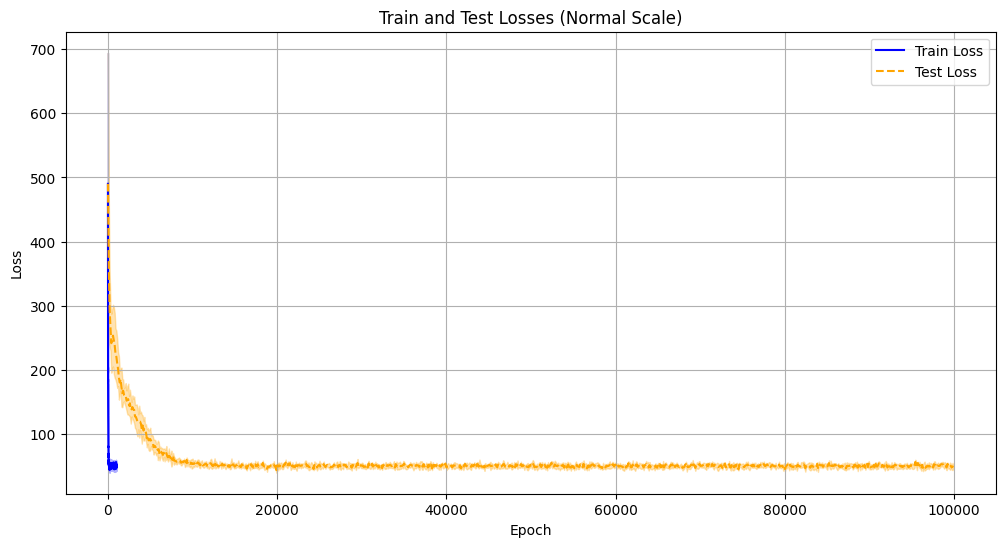

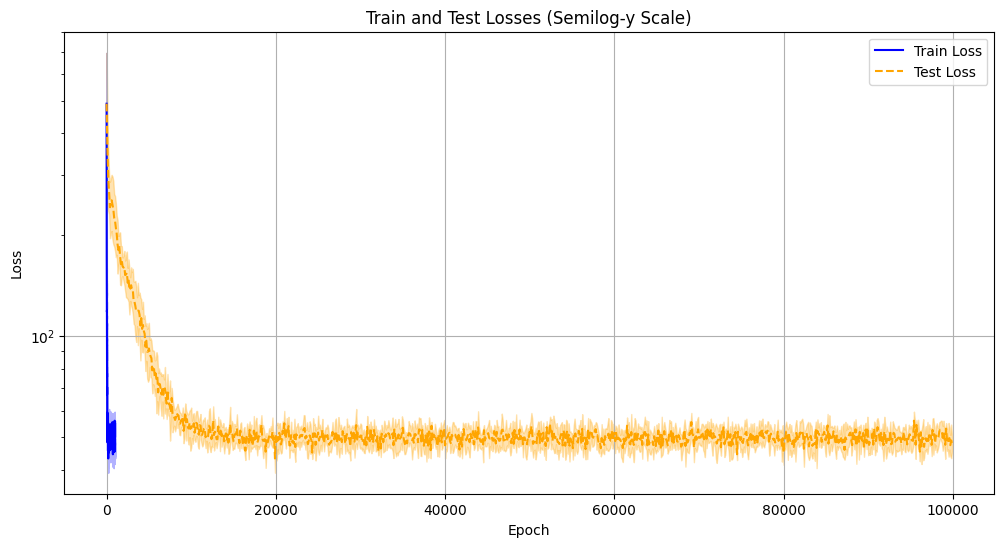

In [24]:
N = 5 # number of runs
num_epochs = 1000

run_multiple_experiments(N, ControlNetworkTimeSpace, train_stochastic_control, num_epochs, batch_size, learning_rate, dt, T, sigma, sigma0, test_size, hidden_dim)